# 07 Fig 2: the event field and the slip model

```
Created on Mon Sep 28 2026
@author: daniellelindsay
Run in opera_disp_feb13, after 06 and 07. Seconds.
```

**What this notebook does.** Draws Fig 2 from the products of notebook 06
(the maps and profiles, `fig2_inputs.npz`) and notebook 07 (the model row,
`fig2_model_row.npz`). It computes no numbers and registers nothing: every
number on the figure was registered where it was made.

Moved out of `06_event_field_geometry` on 2026-09-28 so the model row is the
real model. Fig 2 is the fault-parallel and vertical version (Dani,
2026-09-28); the per-track LOS version is the supplement figure.

**Inputs**: `06_event_field_geometry/fig2_inputs.npz`,
`07_slip_model_tests/fig2_model_row.npz` (placeholders if absent),
`hayward_fault_profiles.csv`, the alignment-array summary.

**Figures**: `fig2_fault_parallel_vertical_coh<c>_<n>ev` (Fig 2) and
`figS_los_maps_profiles_coh<c>_<n>ev` (the LOS version, supplement).

In [1]:
import os

import insar_utils as utils
from TulePond_filepaths import (common_paths, creepmeters, paths_out, dist_min, dist_max,
                                fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km)

import numpy as np
import pandas as pd
import pyproj
import xarray as xr
from scipy.spatial import cKDTree
import pygmt

## Constants

In [2]:
notebook = "07_slip_model_fig2"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)

# the running median drawn on the profiles
median_bin_m = 150.0            # running-median bin (five pixels), taken on each side of the fault separately
median_col, grey, ann_col = "#A50F15", "gray55", "black"       # per-side running median (dark red); pixels; block annotation
model_col = "#0072B2"          # the slip model (notebook 07), blue
xfault_step_m = (dist_min * 1e3, dist_max * 1e3)   # the near-fault band the block amplitudes use (m), for the caption

# Fig 2 map window (unrotated, north up): centred on the trace at map_centre_km from Point Pinole,
# +/- map_half_km east-west, +/- (map_half_km + map_extra_km) north-south, as the draft (10.4 x 12 km).
# The values live in TulePond_filepaths so Fig 1 (notebook 04) draws the same box.
map_centre_km, map_half_km, map_extra_km = fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km
aa_labelled = ["HGIL", "HRKT"]  # the arrays named in the paper (notebook 08); the other arrays of the section are not drawn
aa_label_pos = {"HGIL": ("RM", "-0.15c/0c"), "HRKT": ("LM", "0.15c/0.12c")}   # (justify, offset) of each label about its symbol

f_fig2_in = os.path.join(paths_out["06_event_field_geometry"], "fig2_inputs.npz")
aa_file = common_paths["aa_summary"]

## Load: the maps and profiles from notebook 06, the trace

The per-track maps and profiles were made in 06; here they are only unpacked
into the same names 06 used, so the drawing code reads the same.

In [3]:
z = np.load(f_fig2_in)
print(str(z["provenance"]))
lon_g, lat_g, Xg, Yg = z["lon"], z["lat"], z["X"], z["Y"]
nr, nc = lon_g.shape
strike, coh_maps, cross_m = float(z["strike"]), float(z["coh_maps"]), float(z["cross_m"])
names = [str(n_) for n_ in z["names"]]
tracks = ["ascending", "descending"]
event_maps = {o: dict(rate=z[f"rate_{o}"]) for o in tracks}
mean_event = {o: dict(mean=z[f"event_{o}"], n=int(z["n_events"])) for o in tracks}
fp_rate, fp_evt = z["fp_rate"], z["fp_event"]
up_rate, up_evt = z["up_rate"], z["up_event"]


def unpack(field):
    """The profiles of one field (fp, ascending, descending) as 06 held them."""
    out = {}
    for n_ in names:
        p = {k: z[f"prof_{field}_{n_}_{k}"] for k in ("d", "v", "de", "ve", "ends")}
        p["blocks"] = {blk: dict(amp=float(z[f"prof_{field}_{n_}_{blk}_amp"]), se=float(z[f"prof_{field}_{n_}_{blk}_se"]))
                       for blk in ("W", "E")}
        out[n_] = p
    return out


profiles = unpack("fp")
up_profiles = unpack("up")
los_profiles = {o: unpack(o) for o in tracks}

# the grid: pixel centres on a regular UTM lattice (asserted), so a pixel is found by its index
epsg = int(z["epsg"])
to_utm = pyproj.Transformer.from_crs(4326, epsg, always_xy=True)
to_ll = pyproj.Transformer.from_crs(epsg, 4326, always_xy=True)
dx, dy = float(Xg[0, 1] - Xg[0, 0]), float(Yg[1, 0] - Yg[0, 0])
assert np.allclose(np.diff(Xg, axis=1), dx) and np.allclose(np.diff(Yg, axis=0), dy), "the 06 grid is not regular"
x_origin, y_origin = float(Xg[0, 0]) - 0.5 * dx, float(Yg[0, 0]) - 0.5 * dy     # outer corner of the first pixel

# the trace, and the unit normal pointing to the east (NE) block, as in 06
prof = pd.read_csv(common_paths["fault_profiles"])
fx, fy = to_utm.transform(prof.ft_lon.values, prof.ft_lat.values)
tree = cKDTree(np.c_[fx, fy])
nrm = np.array([np.sin(np.deg2rad(strike - 90)), np.cos(np.deg2rad(strike - 90))])


def running_median(d, v, bin_m=median_bin_m):
    """Binned median on each side of the fault separately: the bin edges start at
    the trace and run outward, so no bin (and no drawn segment) straddles the
    fault. Returns a list of (x, median) arrays, one per side (west, east)."""
    out = []
    for sgn in (-1, 1):
        edges = np.sort(sgn * np.arange(0.0, cross_m + bin_m, bin_m))
        idx = np.digitize(d, edges)
        xc, med = [], []
        for i in range(1, len(edges)):
            m_ = (idx == i) & (sgn * d > 0)
            if m_.sum() >= 3:
                xc.append(0.5 * (edges[i - 1] + edges[i])); med.append(np.median(v[m_]))
        out.append((np.array(xc), np.array(med)))
    return out

06_event_field_geometry | git 3b3680d+ | 2026-09-28 23:18


## Fig S: the observations on each track, and the model row (notebook 07)

Layout (Dani's sketch, 2026-09-23). Row 1, the inter-event rate: the
ascending and descending LOS maps sharing one colour bar, then the X-X' and
Y-Y' profiles of each track (pixels in grey, a per-side running median in
blue). Row 2, the mean event: the same, with each block's near-fault amplitude
over its own far field (text at the panel bottom). Row 3 is the
model, descending only, which notebook 07 will draw (the quadtree samples,
the model, the residual, and slip with depth); until then it is three
labelled empty frames of the sizes 07 will fill, so the page can be judged.
The maps are LOS, positive toward the satellite, so the same right-lateral
step is blue-over-red on ascending and red-over-blue on descending. The
fault-parallel maps and profiles this figure used to show are now a
supplementary figure (next section).

map window: 10.4 x 12 km about 59.5 km (37.5547 N)
alignment arrays in the window: HAPP, HCAM, HGIL, HHAN, HONO, HPIN, HPMD, HRKT, HSGR, HUNI
map panels 3.59 x 4.05 cm; figure ~18.1 x 15.5 cm
common pixel mask for the four maps: 149115 pixels (27% of the box)


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/figS_los_maps_profiles_coh0.9_5ev.png


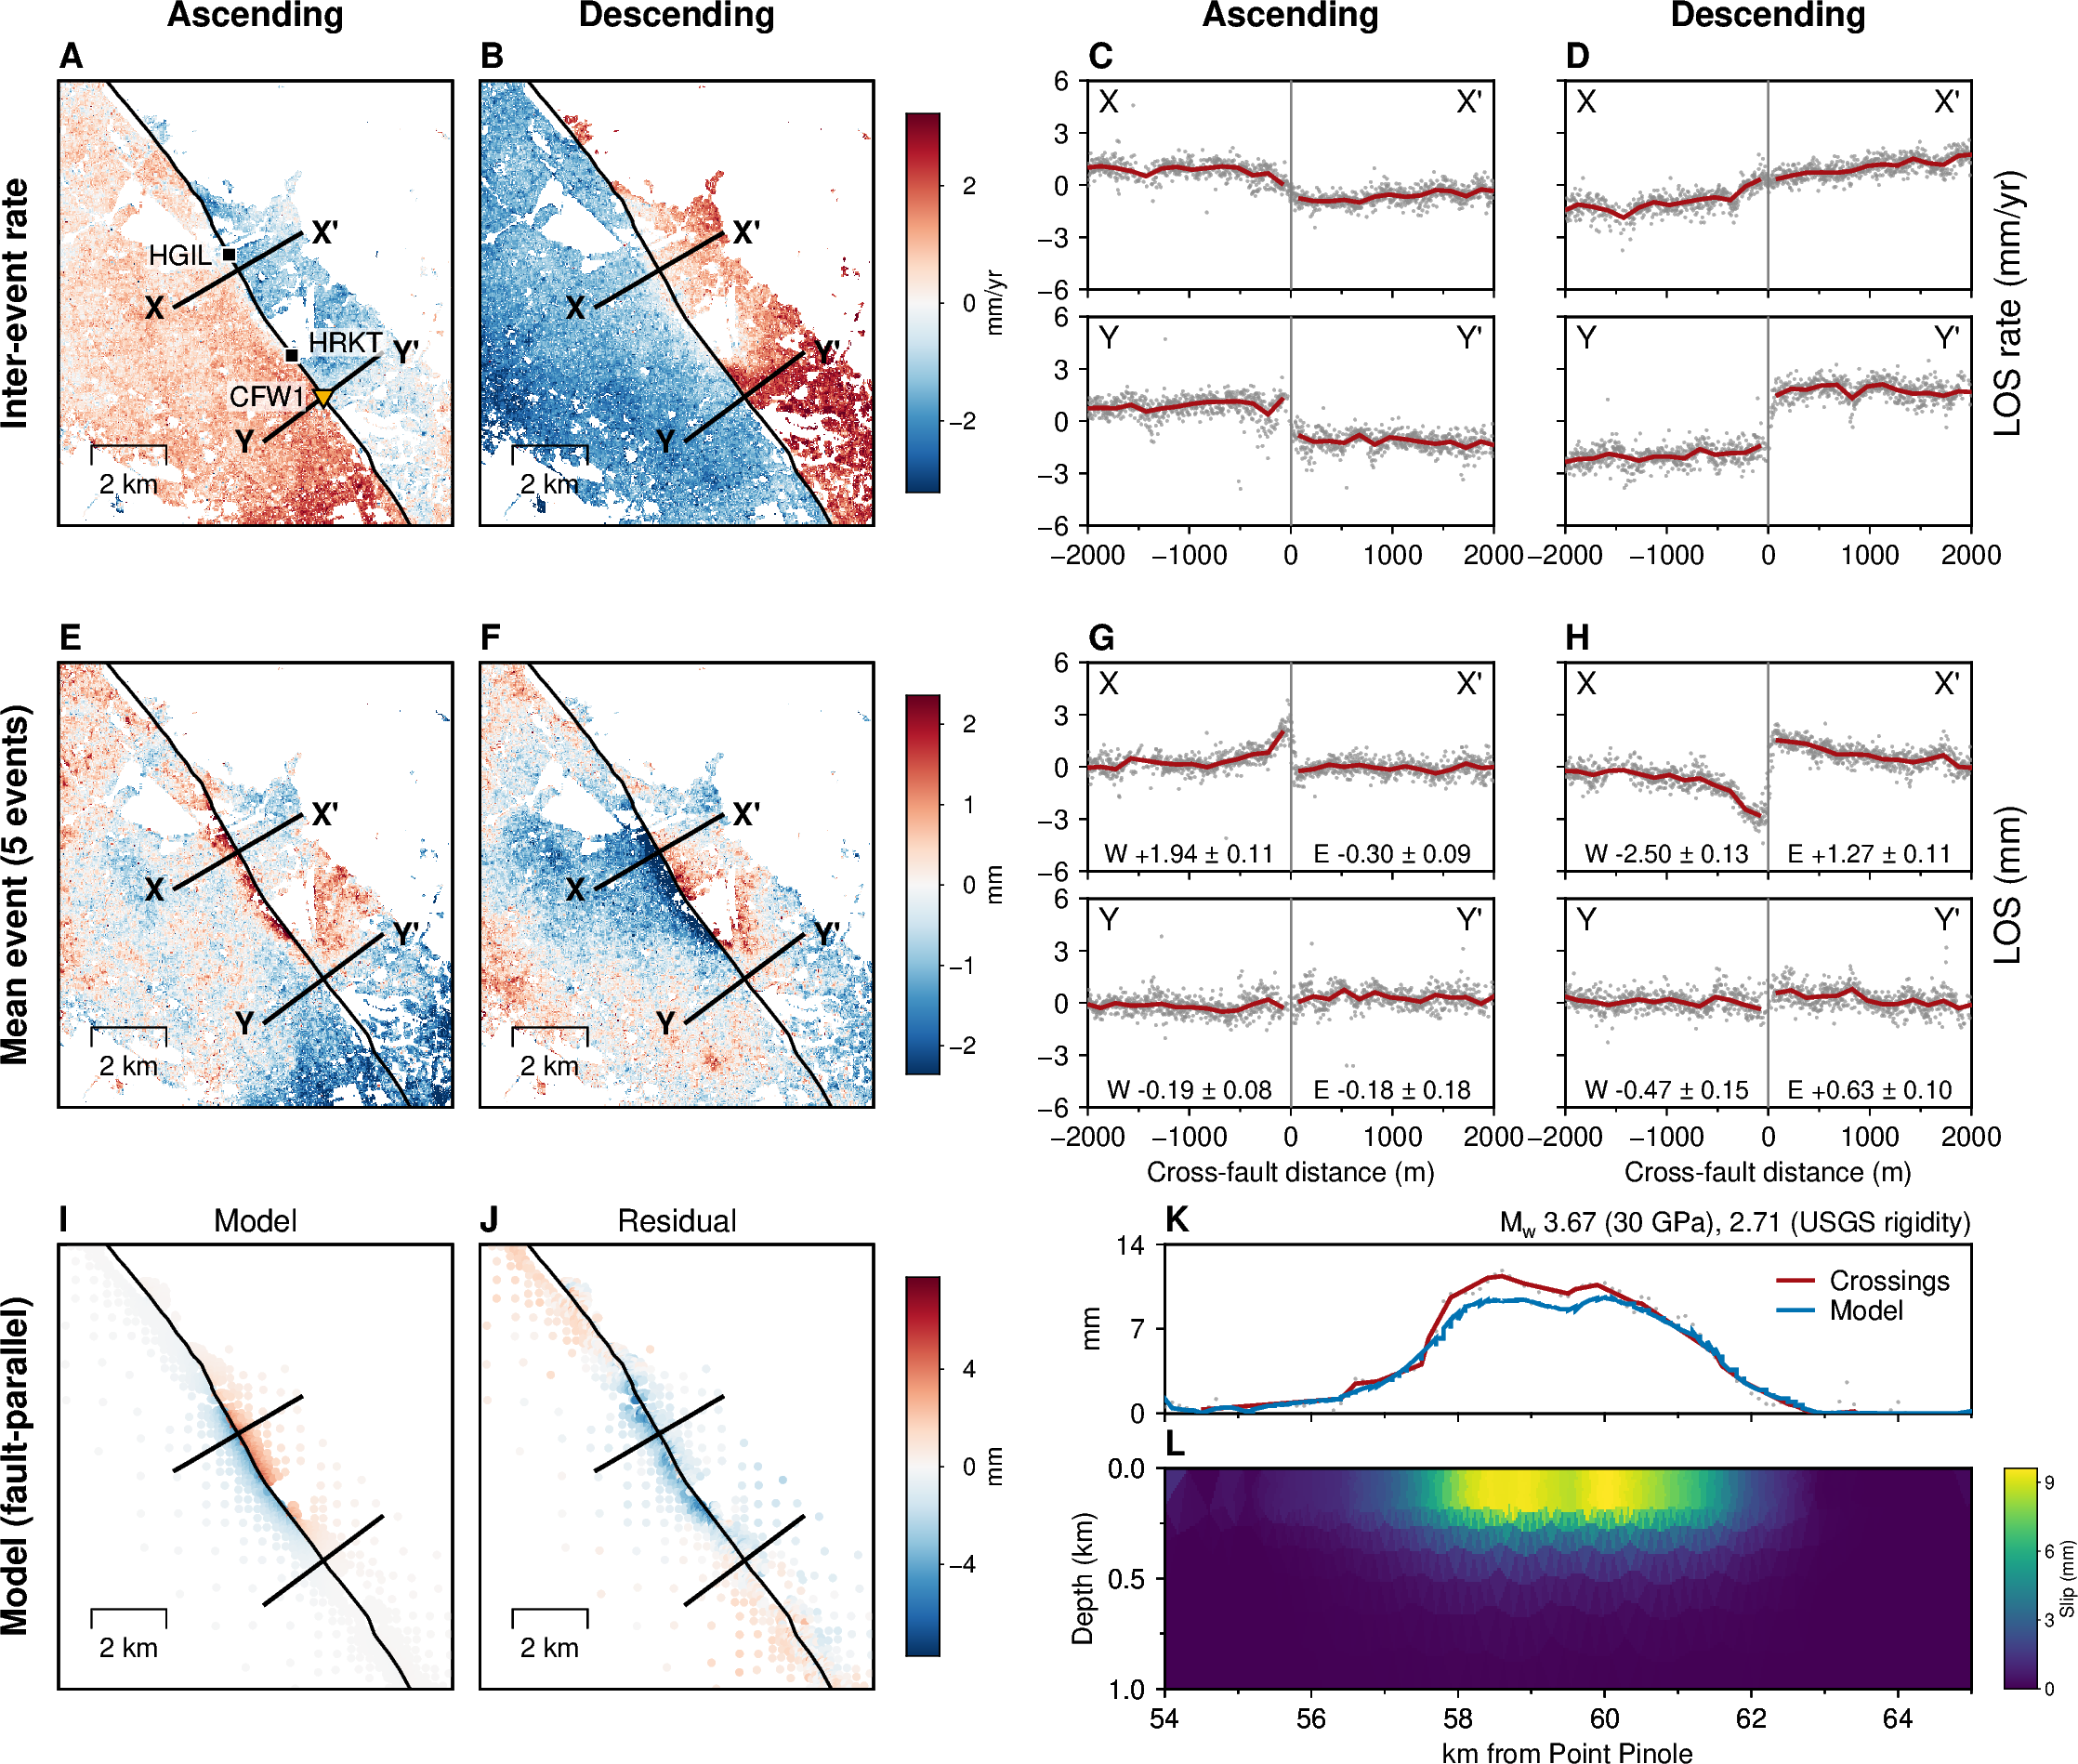

In [4]:
# --- the map window: a lon/lat box about the trace point map_centre_km from Point Pinole
km_of = utils.lat_to_km_map(common_paths["fault_profiles"])
j_c = int(np.argmin(np.abs(km_of(prof.ft_lat.values) - map_centre_km)))
xc, yc = (float(t_) for t_ in to_utm.transform(prof.ft_lon[j_c], prof.ft_lat[j_c]))
lon_w, lat_s = to_ll.transform(xc - map_half_km * 1e3, yc - (map_half_km + map_extra_km) * 1e3)
lon_e, lat_n = to_ll.transform(xc + map_half_km * 1e3, yc + (map_half_km + map_extra_km) * 1e3)
region_map = [lon_w, lon_e, lat_s, lat_n]
print(f"map window: {2 * map_half_km:g} x {2 * (map_half_km + map_extra_km):g} km about {map_centre_km:g} km ({prof.ft_lat[j_c]:.4f} N)")

# the maps on a regular lon/lat grid (nearest 30 m pixel)
lat_q = np.arange(lat_s - 0.002, lat_n + 0.002, 0.00025)
lon_q = np.arange(lon_w - 0.002, lon_e + 0.002, 0.0003)
LONq, LATq = np.meshgrid(lon_q, lat_q)
Eq, Nq = to_utm.transform(LONq, LATq)
ci = np.round((Eq - x_origin) / dx - 0.5).astype(int); ri = np.round((Nq - y_origin) / dy - 0.5).astype(int)
okq = (ci >= 0) & (ci < nc) & (ri >= 0) & (ri < nr)
_, jq = tree.query(np.c_[Eq.ravel(), Nq.ravel()])
side_q = ((np.c_[Eq.ravel(), Nq.ravel()] - np.c_[fx, fy][jq]) @ nrm).reshape(Eq.shape)    # + east of the trace


def to_grid(m_, balance):
    z = np.full(LONq.shape, np.nan); z[okq] = m_[ri[okq], ci[okq]]
    if balance:                                                 # fault at zero: mid-point of the two block medians in the window
        z -= 0.5 * (np.nanmedian(z[side_q < 0]) + np.nanmedian(z[side_q > 0]))
    lim = max(float(np.nanpercentile(np.abs(z[np.isfinite(z)]), 98)), 0.3)
    return xr.DataArray(z, coords={"lat": lat_q, "lon": lon_q}, dims=("lat", "lon")), lim


def gmt_map_size(region, projection):
    """Width and height (cm) GMT gives a region/projection pair (mapproject -W)."""
    with pygmt.clib.Session() as lib:
        f_ = os.path.join(out_dir, "cpt", "dims.txt")
        lib.call_module("mapproject", f"-R{'/'.join(str(r) for r in region)} -J{projection} -W ->{f_}")
    return tuple(float(x) for x in open(f_).read().split())


cpt_dir = os.path.join(out_dir, "cpt"); os.makedirs(cpt_dir, exist_ok=True)
lines_ll = {n_: to_ll.transform(np.array([p["ends"][0], p["ends"][2]]), np.array([p["ends"][1], p["ends"][3]])) for n_, p in profiles.items()}
cfw = [c for c in creepmeters if c[0] == "CFW1"][0]
aa = utils.load_aa_summary(aa_file)
aa = aa[(aa.long_deg > lon_w) & (aa.long_deg < lon_e) & (aa.lat_deg > lat_s) & (aa.lat_deg < lat_n)]
print("alignment arrays in the window:", ", ".join(aa.site_code))

# --- sizes (cm): a double-column figure (18 cm)
Wp, Hp = 3.7, 1.9                                   # one profile panel
gap_pair, gap_col, gap_row = 0.25, 0.65, 1.25       # within a stacked pair; between the two profile columns (room for the +/-2000 labels); between rows
Hpair = 2 * Hp + gap_pair                           # a stacked pair; the maps are made exactly this tall
w_, h_ = gmt_map_size(region_map, "M4c")
Wm, Hm = 4.0 * Hpair / h_, Hpair
proj_map = f"M{Wm:.3f}c"
gap_map, cb_w, gap_cb = 0.25, 0.3, 0.3              # between the two maps; colour-bar width; map-to-bar gap
x_prof = 2 * Wm + gap_map + gap_cb + cb_w + 1.35    # left edge of the profile columns (room for the bar label and the y annotation)
W_model = 2 * Wp + gap_col                          # the slip-model panel spans both profile columns
print(f"map panels {Wm:.2f} x {Hm:.2f} cm; figure ~{x_prof + W_model + 0.7:.1f} x {3 * Hpair + 2 * gap_row + 0.9:.1f} cm")
lim_prof = {"rate": 6.0, "event": 6.0}              # LOS profile axes (mm/yr, mm); the FP figure uses 10
n_mean = mean_event["ascending"]["n"]
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p", FORMAT_GEO_MAP="ddd.xx")
fig = None                      # the helpers below draw into the module-level figure that draw_fig2 creates


def map_base(grid, cpt, label, stations=True):
    """One map, north up, in lon/lat: the field, the trace, the profile lines, and (stations=True) CFW1 and the alignment arrays. No colour bar."""
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
    fig.grdimage(grid=grid, cmap=cpt, nan_transparent=True)
    fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
    for n_, (llon, llat) in lines_ll.items():
        fig.plot(x=llon, y=llat, pen="1.0p,black")
        fig.text(x=llon[0], y=llat[0], text=n_, justify="RM", offset="-0.08c/0c", font="8p,Helvetica-Bold")
        fig.text(x=llon[1], y=llat[1], text=n_ + "'", justify="LM", offset="0.08c/0c", font="8p,Helvetica-Bold")
    if stations:
        used = aa.site_code.isin(aa_labelled)                                    # only the arrays the paper uses are drawn
        fig.plot(x=aa.long_deg.values[used], y=aa.lat_deg.values[used], style="s0.18c", fill="black", pen="0.4p,white")
        for _, r_ in aa[used].iterrows():                                          # HGIL left of its symbol, HRKT right and nudged up off the Y-Y' line
            just, off = aa_label_pos[r_.site_code]
            utils.text_backed(fig, x=r_.long_deg, y=r_.lat_deg, text=r_.site_code, justify=just, offset=off, font="7p,Helvetica")
        fig.plot(x=[cfw[2]], y=[cfw[1]], style="i0.22c", fill="#F5B400", pen="0.5p,black")
        utils.text_backed(fig, x=cfw[2], y=cfw[1], text="CFW1", justify="RM", offset="-0.15c/0c", font="7p,Helvetica")
    fig.text(position="TL", text=label, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)     # Science: bold capital panel letters
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")      # frame on top, scale bar


def colour_bar(cpt, lim, cb_label, x_cm):
    with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):
        fig.colorbar(cmap=cpt, position=f"x{x_cm}c/0.3c+w{Hm - 0.6}c/{cb_w}c+jBL", frame=f"xa{max(1, round(lim / 2)):g}+l{cb_label}")


def los_maps(field, balance, tag, labels, cb_label, row_label, headings=False, stations_on=(), cols=None):
    """The two LOS maps of one row (ascending, descending) from the current origin
    (bottom-left of the ascending map), one shared colour bar right of the
    descending map, the row label left of the ascending map. Leaves the origin
    where it started."""
    cols = cols or tracks
    grids = {o: to_grid(field[o], balance)[0] for o in cols}
    lim = max(max(float(np.nanpercentile(np.abs(g.values[np.isfinite(g.values)]), 98)) for g in grids.values()), 0.3)
    cpt = utils.write_cpt(os.path.join(cpt_dir, f"los_{tag}.cpt"), "RdBu_r", -lim, lim)
    for k, o in enumerate(cols):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        map_base(grids[o], cpt, labels[k], stations=labels[k] in stations_on)     # stations and their labels on panel A only
        if headings:
            fig.text(position="TC", text=o.capitalize(), justify="BC", offset="0c/0.5c", font="9p,Helvetica-Bold", no_clip=True)
    colour_bar(cpt, lim, cb_label, Wm + gap_cb)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text=row_label, angle=90, justify="BC", offset="-0.3c/0c", font="9p,Helvetica-Bold", no_clip=True)
    return lim


def los_profile_pairs(vkey, dkey, lim, labels, ylab, headings=False, xlabel=False, annotate=False, prof_set=None, cols=None, model_lines=None):
    """For each track a stacked pair (X above Y) of LOS profiles, drawn from the
    current origin (bottom-left of the ascending TOP panel). The ascending column
    carries the y annotation, the descending column the y label. Leaves the origin
    at the ascending LOWER panel."""
    for k, o in enumerate(cols or tracks):
        if k:
            fig.shift_origin(xshift=f"{Wp + gap_col}c", yshift=f"{Hp + gap_pair}c")     # next column, back at the top panel
        for j, n_ in enumerate(names):
            p = (prof_set or los_profiles)[o][n_]
            d, v = p[dkey], p[vkey]
            if j > 0:
                fig.shift_origin(yshift=f"-{Hp + gap_pair}c")
            xfr = "xa1000f500+lCross-fault distance (m)" if (j == 1 and xlabel) else "xa1000f500"
            side = ("W" if k == 0 else "w") + ("S" if j == 1 else "s") + "rt"
            fig.basemap(region=[-cross_m, cross_m, -lim, lim], projection=f"X{Wp}c/{Hp}c", frame=[side, xfr, f"ya{lim / 2:g}"])
            fig.plot(x=d, y=v, style="c0.03c", fill=grey, transparency=30)          # the pixels
            for xm, vm in running_median(d, v):                                      # the per-side running median
                fig.plot(x=xm, y=vm, pen="1.0p," + median_col)
            if model_lines and (o, n_) in model_lines:                               # the slip model along the same line (notebook 07)
                d_mod, v_mod = model_lines[(o, n_)]
                for sgn in (-1, 1):                                                  # each side on its own: the model steps at the trace
                    side_ = sgn * d_mod > 0
                    fig.plot(x=d_mod[side_], y=v_mod[side_], pen="1.0p," + model_col)
            if annotate:                                                             # the event: each block's near-fault amplitude over its far field
                for blk, sgn in (("W", -1), ("E", 1)):
                    b_ = p["blocks"][blk]
                    fig.text(x=sgn * 1000, y=-lim, text=f"{blk} {b_['amp']:+.2f} \u00b1 {b_['se']:.2f}", justify="BC", offset="0c/0.08c", font="6.5p,Helvetica," + ann_col)   # bottom: the corners hold X, X'
            fig.plot(x=[0, 0], y=[-lim, lim], pen="0.5p,gray50")
            fig.text(position="TL", text=n_, font="8p,Helvetica", offset="0.1c/-0.08c")
            fig.text(position="TR", text=n_ + "'", font="8p,Helvetica", offset="-0.1c/-0.08c")
            if j == 0:
                fig.text(x=-cross_m, y=lim, text=labels[k], justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
                if headings:
                    fig.text(position="TC", text=o.capitalize(), justify="BC", offset="0c/0.5c", font="9p,Helvetica-Bold", no_clip=True)
    fig.text(position="MR", text=ylab, angle=90, justify="TC", offset=f"0.2c/{0.5 * (Hp + gap_pair)}c", font="9p,Helvetica", no_clip=True)
    fig.shift_origin(xshift=f"-{Wp + gap_col}c")                                     # back to the ascending column (lower panel)


def model_row_placeholder():
    """Row 3 until notebook 07 exists: labelled empty frames of the sizes 07 will draw into."""
    frames = [("I", "Model (quadtree samples)", Wm, Hm, 0.0),
              ("J", "Residual", Wm, Hm, Wm + gap_map),
              ("K", "Slip with depth, Mw", W_model, Hm, x_prof)]
    for lab, txt, w_, h_, x_ in frames:
        fig.shift_origin(xshift=f"{x_}c")
        fig.basemap(region=[0, 1, 0, 1], projection=f"X{w_}c/{h_}c", frame=["lrtb"])
        fig.text(position="TL", text=lab, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
        fig.text(position="MC", text=txt.replace("\n", " "), font="8p,Helvetica,gray40")
        fig.text(position="BC", text="notebook 07", font="7p,Helvetica,gray40", offset="0c/0.15c")
        fig.shift_origin(xshift=f"-{x_}c")
    fig.text(position="ML", text="Model (descending)", angle=90, justify="BC", offset="-0.3c/0c", font="9p,Helvetica-Bold", no_clip=True)


# the model row from notebook 07's product (draft until 07's record run):
# fault-parallel model and residual at the quadtree samples, slip with depth
model_row_file = os.path.join(common_paths["out_dir"], "07_slip_model_tests", "fig2_model_row.npz")


def model_row():
    """Row 3: I the fault-parallel model at the quadtree samples, J the
    residual (shared colour bar right of J), K slip on the unrolled fault
    with Mw. Falls back to the placeholders when 07's product is absent."""
    if not os.path.exists(model_row_file):
        model_row_placeholder()
        return
    z = np.load(model_row_file)
    lim = max(float(np.nanpercentile(np.abs(z["data_mm"]), 98)), 0.3)
    cpt = utils.write_cpt(os.path.join(cpt_dir, "model_fp.cpt"), "RdBu_r", -lim, lim)
    for k, (lab, values) in enumerate((("I", z["model_mm"]), ("J", z["residual_mm"]))):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
        fig.plot(x=z["sample_lon"], y=z["sample_lat"], style="c0.07c", fill=values, cmap=cpt)
        fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
        for n_, (llon, llat) in lines_ll.items():
            fig.plot(x=llon, y=llat, pen="1.0p,black")
        fig.text(position="TL", text=lab, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
        fig.text(position="TC", text=("Model" if lab == "I" else "Residual"), justify="BC", offset="0c/0.12c",
                 font="8p,Helvetica", no_clip=True)
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")
    colour_bar(cpt, lim, "mm", Wm + gap_cb)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text="Model (fault-parallel)", angle=90, justify="BC", offset="-0.3c/0c",
             font="9p,Helvetica-Bold", no_clip=True)
    # K: surface slip along strike, the crossings (04) and the model's surface
    # cells; L: slip with depth on the unrolled fault, top 1 km. Same x axis.
    from matplotlib.tri import Triangulation
    k_indent = 0.7                                       # room for the I/J bar label and the depth label
    Wk, Hk, gap_kl = W_model - k_indent, 0.38 * Hm, 0.5
    Hl = Hm - Hk - gap_kl
    km_view = [54.0, 65.0]
    fig.shift_origin(xshift=f"{x_prof + k_indent}c", yshift=f"{Hl + gap_kl}c")
    slip_top = float(np.ceil(max(np.nanmax(z["crossing_profile_mm"]), np.nanmax(z["surface_model_mm"])) / 2 + 1) * 2)
    region_k = km_view + [0.0, slip_top]
    fig.basemap(region=region_k, projection=f"X{Wk}c/{Hk}c", frame=["Wsrt", "xa2f1", f"ya{slip_top / 2:g}+lmm"])
    fig.plot(x=z["crossing_km"], y=z["crossing_mm"], style="c0.03c", fill=grey, transparency=30)
    fig.plot(x=z["crossing_profile_km"], y=z["crossing_profile_mm"], pen="1.0p," + median_col, label="Crossings")
    fig.plot(x=z["surface_km"], y=z["surface_model_mm"], pen="1.0p," + model_col, label="Model, surface")
    fig.legend(position="jTR+o0.05c/0.05c", box=False)
    fig.text(position="TL", text="K", justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
    fig.text(position="TR", text=f"M@-w@- {float(z['mw_30gpa']):.2f} (30 GPa), {float(z['mw_sfcvm']):.2f} (USGS rigidity)",
             justify="BR", offset="0c/0.12c", font="7p,Helvetica", no_clip=True)
    # L: slip on the unrolled fault, sampled on a regular grid (each triangle's slip is constant over it)
    fig.shift_origin(yshift=f"-{Hl + gap_kl}c")
    nodes_sz, faces_m, slip_m = z["nodes_sz"], z["faces"], z["slip_mm"]
    finder = Triangulation(nodes_sz[:, 0], nodes_sz[:, 1], faces_m).get_trifinder()
    z_max = 1.0
    s_axis = np.arange(nodes_sz[:, 0].min(), nodes_sz[:, 0].max(), 0.025)
    z_axis = np.arange(0.00625, z_max, 0.0125)
    S_, Z_ = np.meshgrid(s_axis, z_axis)
    tri_id = finder(S_, Z_)
    slip_grid = np.where(tri_id >= 0, slip_m[np.maximum(tri_id, 0)], np.nan)
    km_axis = float(z["s0_km_pp"]) + s_axis                    # s grows southward, as km from Point Pinole
    in_view = (km_axis >= km_view[0]) & (km_axis <= km_view[1])
    grid_l = xr.DataArray(slip_grid[:, in_view], coords=dict(depth=z_axis, km=km_axis[in_view]), dims=("depth", "km"))
    slip_max = float(np.nanmax(slip_grid))
    cpt_l = utils.write_cpt(os.path.join(cpt_dir, "slip.cpt"), "viridis", 0.0, slip_max)
    region_l = km_view + [0.0, z_max]
    proj_l = f"X{Wk}c/-{Hl}c"
    fig.basemap(region=region_l, projection=proj_l, frame=["WSrt", "xa2f1+lkm from Point Pinole", "ya0.5f0.25+lDepth (km)"])
    fig.grdimage(grid=grid_l, cmap=cpt_l, nan_transparent=True)
    fig.basemap(region=region_l, projection=proj_l, frame=["WSrt", "xa2f1", "ya0.5f0.25"])
    fig.text(position="TL", text="L", justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
    with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):
        fig.colorbar(cmap=cpt_l, position=f"x{Wk + gap_cb}c/0c+w{Hl}c/{cb_w}c+jBL",
                     frame=f"xa{max(1, round(slip_max / 3)):g}+lSlip (mm)")
    fig.shift_origin(xshift=f"-{x_prof + k_indent}c")

rate_field = {o: event_maps[o]["rate"] for o in tracks}
evt_field = {o: mean_event[o]["mean"] for o in tracks}
common_ok = np.all([np.isfinite(f[o]) for f in (rate_field, evt_field) for o in tracks], axis=0)    # A, B, E, F show the same pixels
rate_field = {o: np.where(common_ok, m_, np.nan) for o, m_ in rate_field.items()}
evt_field = {o: np.where(common_ok, m_, np.nan) for o, m_ in evt_field.items()}
print(f"common pixel mask for the four maps: {common_ok.sum()} pixels ({common_ok.mean():.0%} of the box)")


def draw_fig2(evt_maps_in, evt_profiles, evt_label, stem, rate_maps_in=None, cols=None, ylabs=("LOS rate (mm/yr)", "LOS (mm)"), lims=None, model_lines=None):
    """The whole figure: row 1 the inter-event rate, row 2 the event maps and
    profiles given, row 3 the model placeholders. Saved as <stem>.png/.pdf.
    The two columns are the tracks unless `cols` names other fields (the test below)."""
    global fig
    fig = pygmt.Figure()
    rate_in, lims = (rate_maps_in if rate_maps_in is not None else rate_field), (lims or lim_prof)
    # row 1: the inter-event rate. A, B the maps; C, D the profiles
    los_maps(rate_in, True, "rate", ["A", "B"], "mm/yr", "Inter-event rate", headings=True, stations_on=("A",), cols=cols)
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs("v", "d", lims["rate"], ["C", "D"], ylabs[0], headings=True, cols=cols, prof_set=evt_profiles)   # the profile set holds rate and event
    # row 2: the event. E, F the maps; G, H the profiles
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    los_maps(evt_maps_in, False, "event", ["E", "F"], "mm", evt_label, cols=cols)
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs("ve", "de", lims["event"], ["G", "H"], ylabs[1], xlabel=True, annotate=True, prof_set=evt_profiles, cols=cols,
                      model_lines=model_lines)
    # row 3: the model, notebook 07
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    model_row()
    fig.savefig(stem + ".png", dpi=300, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
    fig.savefig(stem + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
    print("Saved to:", stem + ".png")
    fig.show()


f_fig2 = os.path.join(fig_dir, f"figS_los_maps_profiles_coh{coh_maps:g}_{n_mean}ev")
draw_fig2(evt_field, los_profiles, f"Mean event ({n_mean} events)", f_fig2)     # the mean, not the median (Dani, 2026-09-23): it is the field 07 inverts

## Fig 2: the fault-parallel and vertical fields, and the model row

The paper figure (Dani, 2026-09-28). The same layout as the LOS figure
above, with the two columns the decomposed fault-parallel (positive
right-lateral: the east block moving south-east) and vertical (positive up)
fields from notebook 06, in place of the two tracks. The profiles and block
amplitudes are 06's, the ones its registry holds (`06_XX_*`, `06_YY_*`).

[fault-parallel] X-X': per block W -5.74 +/- 0.32, E +2.21 +/- 0.20 mm
[fault-parallel] Y-Y': per block W -0.46 +/- 0.32, E +1.17 +/- 0.32 mm
[vertical] X-X': per block W +0.37 +/- 0.11, E +0.45 +/- 0.09 mm
[vertical] Y-Y': per block W -0.37 +/- 0.11, E +0.08 +/- 0.15 mm


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/fig2_fault_parallel_vertical_coh0.9_5ev.png


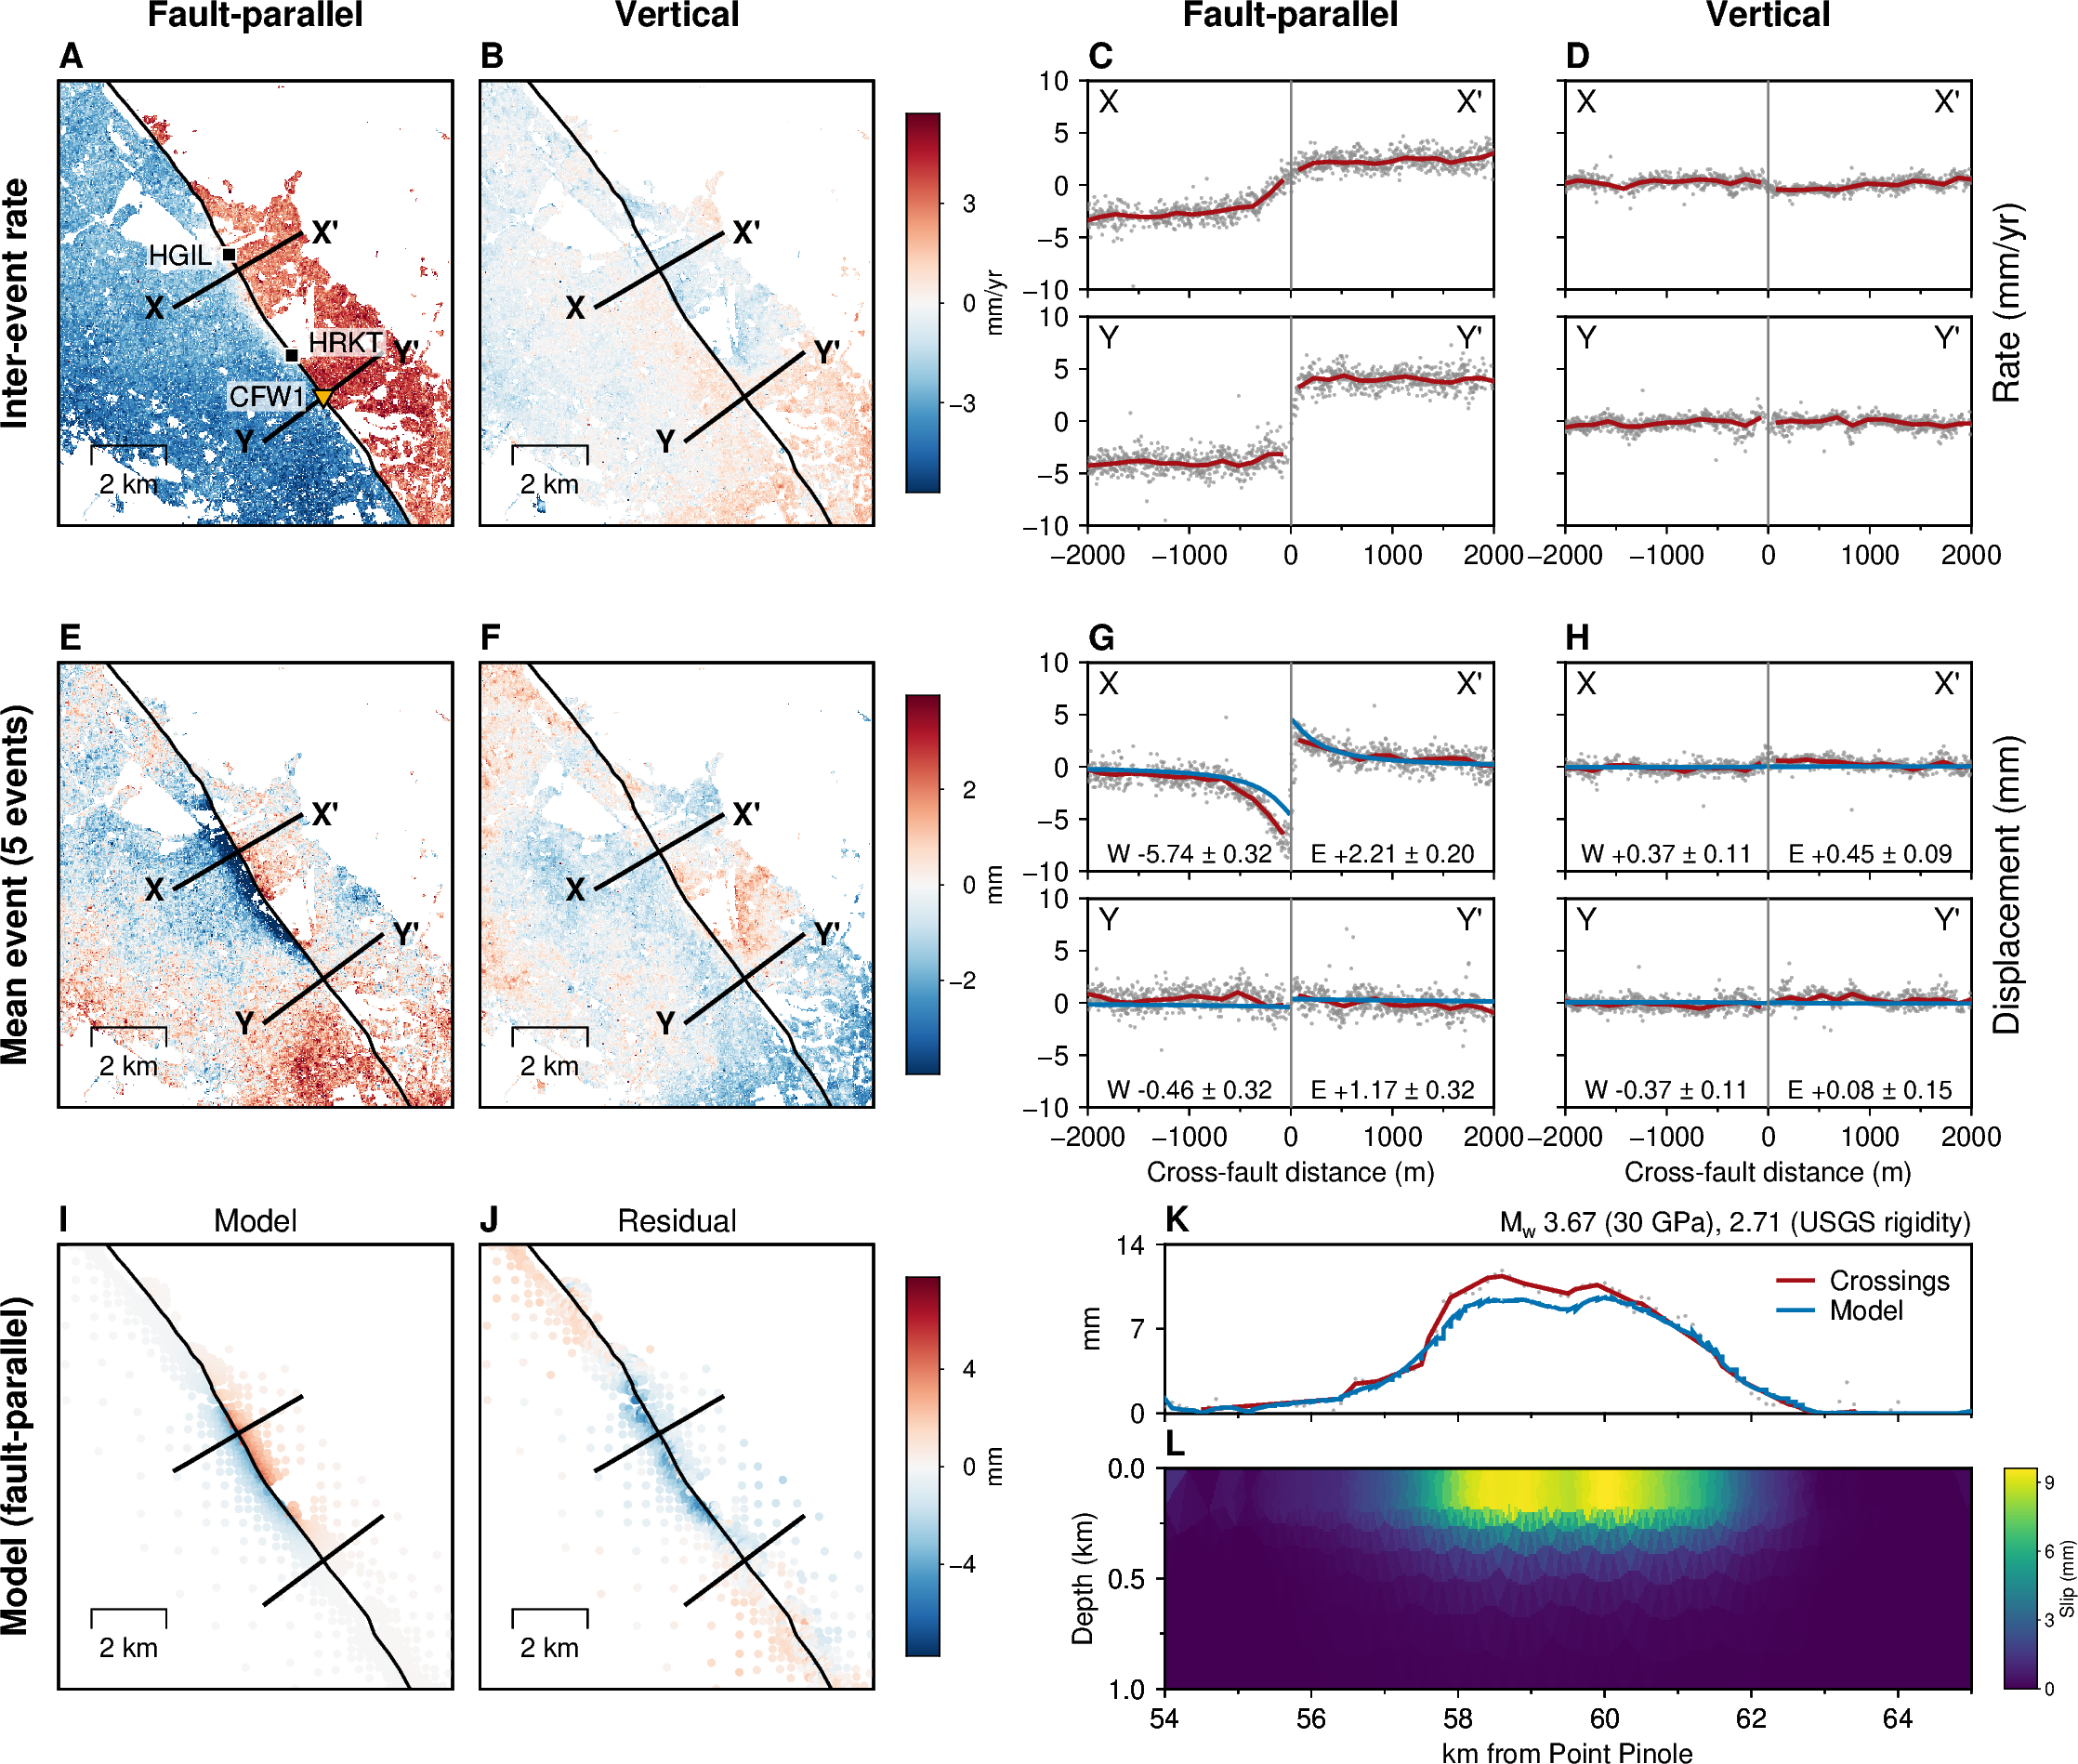

In [5]:
fpup_rate = {"fault-parallel": fp_rate, "vertical": up_rate}
fpup_evt = {"fault-parallel": fp_evt, "vertical": up_evt}
fpup_profiles = {"fault-parallel": profiles, "vertical": up_profiles}
for c in fpup_profiles:
    for n_, p in fpup_profiles[c].items():
        print(f"[{c}] {n_}-{n_}': per block W {p['blocks']['W']['amp']:+.2f} +/- {p['blocks']['W']['se']:.2f}, "
              f"E {p['blocks']['E']['amp']:+.2f} +/- {p['blocks']['E']['se']:.2f} mm")
model_lines = None
if os.path.exists(model_row_file):
    z_model = np.load(model_row_file)
    model_lines = {(col, n_): (z_model[f"prof_{n_}_{key}_d"], z_model[f"prof_{n_}_{key}_mm"])
                   for col, key in (("fault-parallel", "fp"), ("vertical", "up")) for n_ in names}
f_fig2_fp = os.path.join(fig_dir, f"fig2_fault_parallel_vertical_coh{coh_maps:g}_{n_mean}ev")
draw_fig2(fpup_evt, fpup_profiles, f"Mean event ({n_mean} events)", f_fig2_fp,
          rate_maps_in=fpup_rate, cols=list(fpup_rate), ylabs=("Rate (mm/yr)", "Displacement (mm)"),
          lims={"rate": 10.0, "event": 10.0}, model_lines=model_lines)